# 01 · UTD19 – urban traffic loop detectors (Torino extract)

**Utility for the City Brain: very high** · Domain: traffic · Incident types: `traffic_jam`, `accident`

> The only real city traffic stream we have: flow, occupancy and speed every 5 minutes. It shows what rush hour looks like and which jam rules raise false alarms.

| | |
|---|---|
| **Source** | ETH Zurich, https://utd19.ethz.ch (Loder et al. 2019, *Scientific Reports* 9) |
| **Licence** | Free after sign-up, **academic / non-commercial only**: not redistributed here |
| **In this repo** | No data. Outputs below were produced on the full download |
| **Get it** | Register on utd19.ethz.ch, download `utd19_u.csv` (7 GB), `detectors_public.csv`, `links.csv`; extract Torino with `awk -F, '$7=="torino"' utd19_u.csv > torino.csv` |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

`utd19_u.csv` has one row per detector per 5-minute interval, for 39 cities. We use the Torino extract (one of the 9 cities with speed).

| Column | Meaning |
|---|---|
| `day` | Date |
| `interval` | Seconds since midnight (0, 300, …, 86100) |
| `detid` | Detector id |
| `flow` | Vehicles per hour |
| `occ` | Occupancy (% of time a vehicle is over the loop) |
| `error` | Error flag (often empty) |
| `speed` | km/h (only 9 cities have it) |

`detectors_public.csv` (here `torino_dets.csv`) gives each detector's road, road class, lanes, speed limit, `linkid` and position: the material for a graph.

In [2]:
df = pd.read_csv(path('traffic/utd19/torino.csv'))
dets = pd.read_csv(path('traffic/utd19/torino_dets.csv'))
df = df[(df.occ <= 100)]                       # a few occupancy values > 100 % are errors
df['hour'] = df.interval // 3600
df['weekend'] = pd.to_datetime(df.day).dt.day_of_week >= 5
print(f"{len(df):,} rows · {df.detid.nunique()} detectors · {df.day.nunique()} days ({df.day.min()} to {df.day.max()})")
df.head()

2,018,170 rows · 399 detectors · 21 days (2016-09-26 to 2016-10-16)


,day,interval,detid,flow,occ,error,city,speed,hour,weekend
0,2016-09-26,0,230,156,2.860391,NaN,torino,54.538,0,False
1,2016-09-26,300,230,144,2.727789,NaN,torino,52.790,0,False
2,2016-09-26,600,230,228,3.171071,NaN,torino,71.900,0,False
3,2016-09-26,900,230,228,4.319818,NaN,torino,52.780,0,False
4,2016-09-26,1200,230,216,3.578529,NaN,torino,60.360,0,False


In [3]:
dets[['detid', 'road', 'fclass', 'lanes', 'limit', 'linkid', 'lat', 'long']].head()

,detid,road,fclass,lanes,limit,linkid,lat,long
0,230,Via Tommaso Agudio,primary,3,0,113,45.077196,7.729331
1,2012,Corso Giulio Cesare,residential,3,0,85,45.116100,7.709120
2,2016,Corso Casale,primary,2,0,361,45.081100,7.730600
3,2017,Corso Casale,primary,2,0,360,45.082500,7.729700
4,2026,Corso Casale,primary,2,0,380,45.082100,7.730060


## 2. Rush hour: what normal traffic looks like

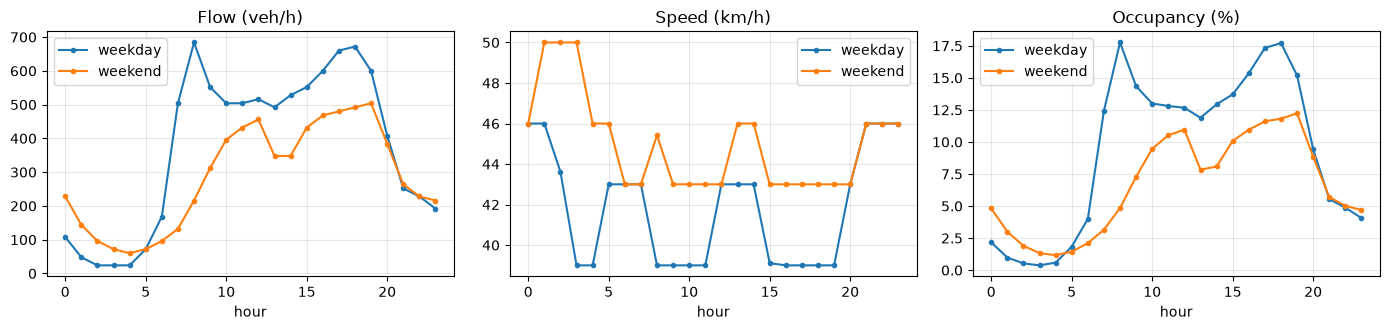

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
weekend,,,,,,,,,,,,,,,,,,,,,,,,
False,108.0,48.0,24.0,24.0,24.0,72.0,168.0,504.0,684.0,552.0,504.0,504.0,516.0,492.0,528.0,552.0,600.0,660.0,672.0,600.0,408.0,252.0,228.0,192.0
True,228.0,144.0,96.0,72.0,60.0,72.0,96.0,132.0,216.0,312.0,396.0,432.0,456.0,348.0,348.0,432.0,468.0,480.0,492.0,504.0,384.0,264.0,228.0,216.0


In [4]:
prof = df.groupby(['weekend', 'hour'])[['flow', 'speed', 'occ']].median().unstack(0)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for i, c in enumerate(['flow', 'speed', 'occ']):
    prof[c].plot(ax=ax[i], marker='.')
    ax[i].set_title({'flow': 'Flow (veh/h)', 'speed': 'Speed (km/h)', 'occ': 'Occupancy (%)'}[c]); ax[i].set_xlabel('hour')
    ax[i].legend(['weekday', 'weekend'])
plt.tight_layout(); plt.show()
prof['flow'].round(0).T

Weekday flow has two peaks (about 8h and 17–18h) and is near zero at night; speed barely drops at rush hour. Weekends have no morning peak. **A per-detector, per-hour, weekday/weekend baseline is needed**: a fixed threshold can't fit both 3h and 8h.

## 3. Testing jam rules on 21 normal days

All 21 days are normal days (no labelled incident), so **every alarm is (almost certainly) a false alarm**. We count *episodes* (runs of consecutive alarming intervals) per detector per day.

In [5]:
d = df.dropna(subset=['speed']).sort_values(['detid', 'day', 'interval']).copy()
base = d.groupby(['detid', 'weekend', 'hour']).speed.median().rename('base')
d = d.join(base, on=['detid', 'weekend', 'hour'])
overall = d.groupby('detid').speed.median().rename('overall')
d = d.join(overall, on='detid')

def episodes(cond, min_len):
    """Episodes per detector-day: runs of >= min_len consecutive intervals where cond is true."""
    g = d.detid.astype(str) + d.day
    run_id = ((cond != cond.shift()) | (g != g.shift())).cumsum()
    runs = cond.groupby(run_id).agg(['first', 'size'])
    n = ((runs['first']) & (runs['size'] >= min_len)).sum()
    return n / g.nunique()

rules = {
    'speed < 20 km/h (3 x 5 min)': (d.speed < 20, 3),
    'speed < 50 % of overall median': (d.speed < 0.5 * d.overall, 3),
    'speed < 50 % of same-hour baseline': (d.speed < 0.5 * d.base, 3),
    '  + occupancy >= 25 %': ((d.speed < 0.5 * d.base) & (d.occ >= 25), 3),
    '  + occupancy >= 25 % for 30 min': ((d.speed < 0.5 * d.base) & (d.occ >= 25), 6),
}
res = pd.Series({k: episodes(c, n) for k, (c, n) in rules.items()}, name='false alarms per detector-day')
res.round(3).to_frame()

,false alarms per detector-day
speed < 20 km/h (3 x 5 min),1.880
speed < 50 % of overall median,1.228
speed < 50 % of same-hour baseline,0.673
+ occupancy >= 25 %,0.180
+ occupancy >= 25 % for 30 min,0.040


In [6]:
night = d[(d.speed < 20)]
print('Hour of "speed < 20" readings (top 5):', night.hour.value_counts().head().to_dict())
print('Median flow during those readings:', night.flow.median())
print('Share of 5-min steps with a >= 50 % speed drop:',
      round((d.groupby('detid').speed.pct_change() <= -0.5).mean() * 100, 1), '%')

Hour of "speed < 20" readings (top 5): {3: 20337, 4: 17315, 2: 15843, 5: 10384, 1: 10303}
Median flow during those readings: 36.0
Share of 5-min steps with a >= 50 % speed drop: 4.6 %


The naive rule fires mostly at night, when **no cars pass** (flow ≈ 0, so speed means nothing). Each condition removes a class of false alarms; the final rule (same-hour baseline + occupancy + 30 min) leaves only real rush-hour queues. A sudden 50 % speed drop in one step is common, so on its own it's noise.

## 4. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | `traffic_jam` = speed < 50 % of same-hour, same-day-type baseline **and** occupancy ≥ 25 % for 30 min **and** ≥ 2 neighbouring detectors; ignore speed when flow ≈ 0. A single speed drop is not an `accident` |
| **Graph** | `detectors → linkid → road` and positions give a realistic sensor → road → neighbour structure for `NEXT_TO` links |
| **Mock** | Replay real weekdays for `traffic_speed` / flow sensors; test case "rush hour, no false jam" |
| **Scenarios** | Normal day (must stay silent), night (empty road), weekend |

**Limits:** no labelled incidents (can't measure recall); speed in only 9 cities; some detectors are silent for long periods (normal in real life); academic licence only.